# Task 1 - HAB prediction: class imbalance check

The target is `HAB` (0 = no occurrence, 1 = occurrence). This notebook answers one question from section 3.1 of the
lab manual: **are the classes balanced?**

It also looks at how the imbalance varies by year, season and spatial cluster. Finally, it repeats the check on rows with
complete CHL values, because the manual says the 2021-2023 test set contains only complete samples.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path("classification_task1_train.csv")
TARGET = "HAB"
CHL_COLUMNS = ["CHL", "CHL_uncertainty"]
GROUPS = {"Year": "Year", "Season": "Season", "spatial_cluster": "Spatial cluster"}
SEASON_ORDER = ["Winter", "Spring", "Summer", "Fall"]

BAR_COLOR = "#2a78d6"
REFERENCE_COLOR = "#52514e"
GRID_COLOR = "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRID_COLOR,
    "axes.axisbelow": True,
    "font.size": 10,
})

## 1. Load the data

In [2]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig", parse_dates=["Date"])
df = df.sort_values("Date", kind="stable").reset_index(drop=True)

print(f"{df.shape[0]} rows, {df.shape[1]} columns, {df['Date'].min():%Y-%m-%d} to {df['Date'].max():%Y-%m-%d}")
print(f"Missing target values: {df[TARGET].isna().sum()}")
df.head()

1063 rows, 12 columns, 2013-02-19 to 2020-12-29
Missing target values: 0


,Date,Day,Month,Year,Season,CHL,CHL_uncertainty,SST,UI,YDOY,spatial_cluster,HAB
0,2013-02-19,19,2,2013,Winter,NaN,NaN,12.63,0.003952,0.651899,0,0
1,2013-02-19,19,2,2013,Winter,NaN,NaN,12.66,0.000897,0.651899,4,0
2,2013-02-20,20,2,2013,Winter,NaN,NaN,12.63,-0.127962,0.638749,4,0
3,2013-02-26,26,2,2013,Winter,2.705982,54.82,12.66,0.141232,0.556017,4,0
4,2013-02-27,27,2,2013,Winter,NaN,NaN,12.54,0.949088,0.541628,0,0


## 2. Overall class balance

In [3]:
def class_balance(data):
    """Return the count and share of each HAB class."""
    counts = data[TARGET].value_counts().sort_index()
    return pd.DataFrame({"count": counts, "share (%)": (counts / counts.sum() * 100).round(1)})


overall = class_balance(df)
negatives, positives = overall["count"]

print(f"Imbalance ratio (class 0 : class 1): {negatives / positives:.2f} : 1")
print(f"Accuracy of always predicting class 0: {negatives / len(df):.1%}")
overall

Imbalance ratio (class 0 : class 1): 6.70 : 1
Accuracy of always predicting class 0: 87.0%


,count,share (%)
HAB,,
0,925,87.0
1,138,13.0


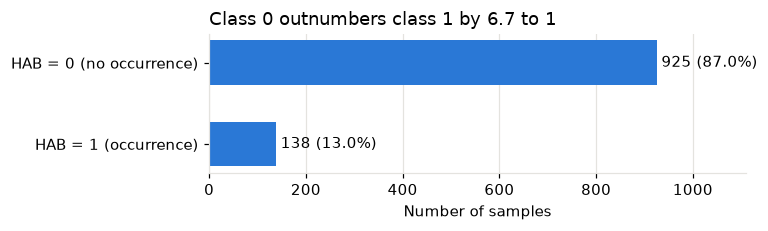

In [4]:
fig, ax = plt.subplots(figsize=(7, 2.2))
labels = ["HAB = 0 (no occurrence)", "HAB = 1 (occurrence)"]
ax.barh(labels, overall["count"], color=BAR_COLOR, height=0.55)
ax.invert_yaxis()
for i, (count, share) in enumerate(zip(overall["count"], overall["share (%)"])):
    ax.text(count + 10, i, f"{count} ({share}%)", va="center")
ax.set_xlim(0, overall["count"].max() * 1.2)
ax.set_xlabel("Number of samples")
ax.xaxis.grid(True, color=GRID_COLOR)
ax.set_title(f"Class 0 outnumbers class 1 by {negatives / positives:.1f} to 1", loc="left")
fig.tight_layout()
plt.show()

## 3. HAB rate by year, season and spatial cluster

A single overall number can hide large differences between groups. Each bar below shows the percentage of samples with
`HAB = 1`, labelled as positives / samples. Small groups give unreliable rates, so read the rate together with its label.

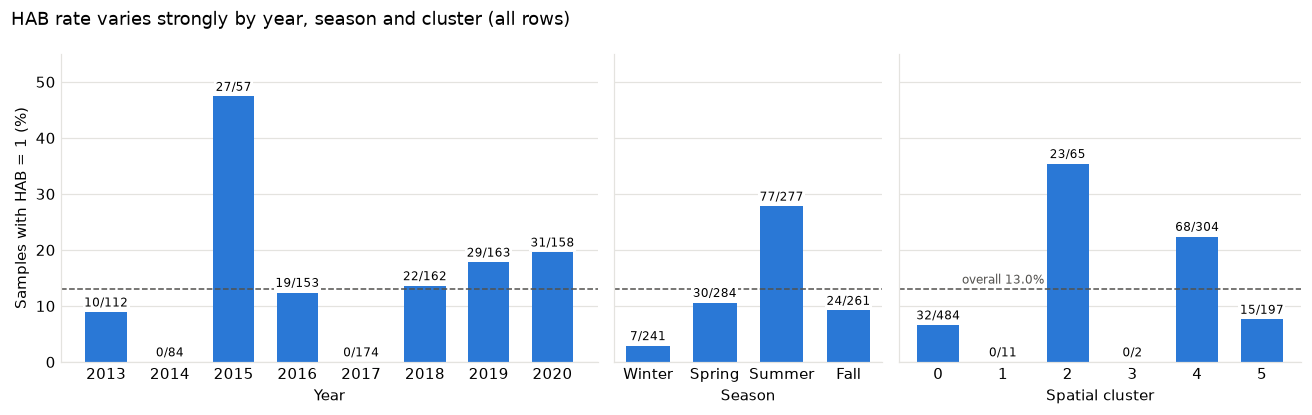

In [5]:
def hab_summary(data, column):
    """Return samples, positives and HAB rate for each value of a column."""
    summary = data.groupby(column)[TARGET].agg(samples="size", positives="sum")
    summary["rate"] = (summary["positives"] / summary["samples"] * 100).round(1)
    return summary.reindex(SEASON_ORDER) if column == "Season" else summary


def plot_hab_rate(data, title):
    """Draw one panel of HAB rates per grouping, on a shared y-axis."""
    overall_rate = data[TARGET].mean() * 100
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True, width_ratios=[8, 4, 6])
    for ax, (column, label) in zip(axes, GROUPS.items()):
        summary = hab_summary(data, column)
        positions = list(range(len(summary)))
        ax.bar(positions, summary["rate"], color=BAR_COLOR, width=0.65)
        ax.axhline(overall_rate, color=REFERENCE_COLOR, linestyle="--", linewidth=1)
        for i, row in enumerate(summary.itertuples()):
            ax.text(i, row.rate + 1, f"{row.positives}/{row.samples}", ha="center", fontsize=8, zorder=5,
                    bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
        ax.set_xticks(positions, summary.index.astype(str))
        ax.set_xlabel(label)
        ax.yaxis.grid(True, color=GRID_COLOR)
        ax.tick_params(length=0)
    axes[0].set_ylabel("Samples with HAB = 1 (%)")
    axes[0].set_ylim(0, 55)
    axes[-1].text(1, overall_rate + 1, f"overall {overall_rate:.1f}%", ha="center",
                  color=REFERENCE_COLOR, fontsize=8)
    fig.suptitle(title, x=0.01, ha="left")
    fig.tight_layout()
    plt.show()


plot_hab_rate(df, "HAB rate varies strongly by year, season and cluster (all rows)")

In [6]:
for column in GROUPS:
    display(hab_summary(df, column).rename(columns={"rate": "HAB rate (%)"}))

,samples,positives,HAB rate (%)
Year,,,
2013,112,10,8.9
2014,84,0,0.0
2015,57,27,47.4
2016,153,19,12.4
2017,174,0,0.0
2018,162,22,13.6
2019,163,29,17.8
2020,158,31,19.6


,samples,positives,HAB rate (%)
Season,,,
Winter,241,7,2.9
Spring,284,30,10.6
Summer,277,77,27.8
Fall,261,24,9.2


,samples,positives,HAB rate (%)
spatial_cluster,,,
0,484,32,6.6
1,11,0,0.0
2,65,23,35.4
3,2,0,0.0
4,304,68,22.4
5,197,15,7.6


## 4. Rows with complete CHL values

The test set contains only complete samples, so the complete rows here are the closest match to it in the training data.

In [7]:
is_complete = df[CHL_COLUMNS].notna().all(axis=1)
complete = df[is_complete]

comparison = pd.DataFrame({
    "All rows": [len(df), df[TARGET].sum()],
    "Complete CHL": [len(complete), complete[TARGET].sum()],
    "Missing CHL": [(~is_complete).sum(), df.loc[~is_complete, TARGET].sum()],
}, index=["samples", "positives"]).T
comparison["HAB rate (%)"] = (comparison["positives"] / comparison["samples"] * 100).round(1)
comparison["ratio (0 : 1)"] = ((comparison["samples"] - comparison["positives"]) / comparison["positives"]).round(2)

print(f"Rows missing CHL: {(~is_complete).mean():.1%}")
comparison

Rows missing CHL: 47.0%


,samples,positives,HAB rate (%),ratio (0 : 1)
All rows,1063,138,13.0,6.70
Complete CHL,563,83,14.7,5.78
Missing CHL,500,55,11.0,8.09


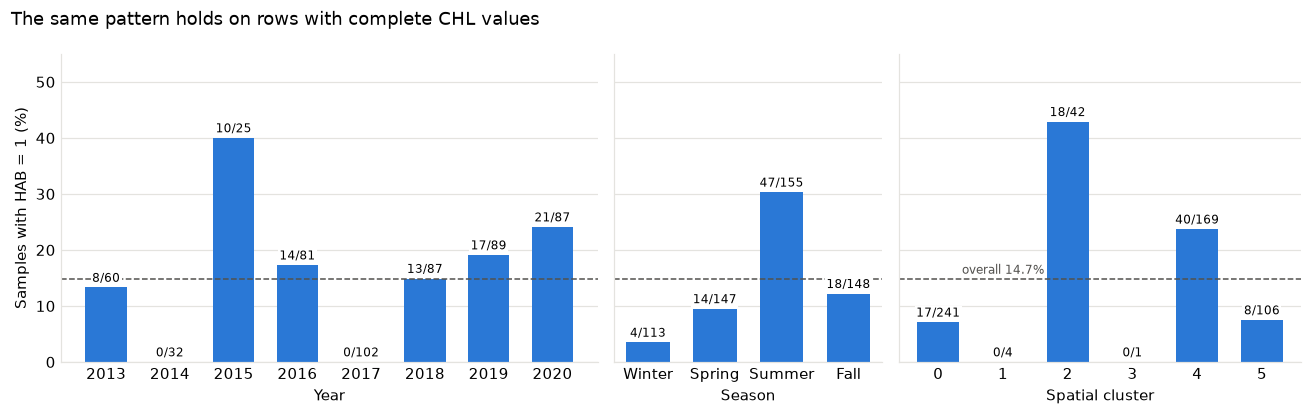

In [8]:
plot_hab_rate(complete, "The same pattern holds on rows with complete CHL values")

In [9]:
for column in GROUPS:
    display(hab_summary(complete, column).rename(columns={"rate": "HAB rate (%)"}))

,samples,positives,HAB rate (%)
Year,,,
2013,60,8,13.3
2014,32,0,0.0
2015,25,10,40.0
2016,81,14,17.3
2017,102,0,0.0
2018,87,13,14.9
2019,89,17,19.1
2020,87,21,24.1


,samples,positives,HAB rate (%)
Season,,,
Winter,113,4,3.5
Spring,147,14,9.5
Summer,155,47,30.3
Fall,148,18,12.2


,samples,positives,HAB rate (%)
spatial_cluster,,,
0,241,17,7.1
1,4,0,0.0
2,42,18,42.9
3,1,0,0.0
4,169,40,23.7
5,106,8,7.5


## 5. Findings

**The classes are imbalanced.**
- There are 925 samples of class 0 and 138 of class 1, so only 13.0% are positive (a ratio of 6.70 : 1).
- Always predicting class 0 reaches 87.0% accuracy while finding no HAB events, so accuracy alone is not a useful measure here.
  On the manual's primary metric, AUC, a model that gives every sample the same score gets only 0.5.
- Rows with complete CHL values are slightly less imbalanced: 14.7% positive (5.78 : 1), against 11.0% in rows missing CHL.

**The imbalance isn't uniform.** These figures are for all rows:
- **Year:** the HAB rate ranges from 0% to 47.4%. 2014 and 2017 have no positives, and 2015 has 27 in 57 samples.
- **Season:** the rate goes from 2.9% in winter to 27.8% in summer.
- **Spatial cluster:** cluster 2 has the highest rate (35.4%), and clusters 1 and 3 have no positives but only 13 samples between them.

**What this means for the next steps:**
- Validation folds need checking for positives, because a fold holding only 2014 or 2017 has no positives and its AUC is undefined.
- A chronological split will see a different class balance in each fold, so a single split could give a misleading score.
- Class weighting or resampling is worth comparing during model selection, applied to the training folds only.

**Differences from the manual:**
- The day-of-year column is called `YDOY` in the data, not `DOY`.
- CHL is missing in 47.0% of rows, while the manual says 46%.